**Case 1: Bhotekoshi glacier collapse and debris flood, Nepal (August 2026)** <br/>

On the morning of 26 August 2026, a huge slab of rock and glacier ice broke off the north face of Langtang Lirung and fell about 1,200 m into the valley below, briefly damming the river. The flood of water and debris that followed swept down the Bhote Koshi, through Rasuwagadhi, Timure and Syabrubesi, killing more than 1,400 people

This notebook looks at what NISAR saw in the weeks before, during and after: whether anything changed beforehand that could have been an early sign, what the flood changed along the valley, and what stood in its way

**Main sources** <br/>

- [Challenge resources](https://www.spaceappschallenge.org/2026/challenges/dancing-with-the-sars/?tab=resources)

- [NASA Earthdata Search](https://search.earthdata.nasa.gov/search)

- [CMR search API](https://cmr.earthdata.nasa.gov/search/site/docs/search/api.html)

- [NISAR Data User Guide](https://nisar-docs.asf.alaska.edu/)

- [Earthdata Login](https://urs.earthdata.nasa.gov/)

**Summary** <br/>

- 
- 
- 
- 


<br/>
<br/>

### 1. Data Retrieval (API Connection)

Find the NISAR data for this case through **[CMR (Common Metadata Repository)](https://www.earthdata.nasa.gov/about/esdis/eosdis/cmr)**, NASA's catalogue of every Earthdata dataset ([Earthdata Search](https://www.earthdata.nasa.gov/learn/earthdata-search) runs on it), then check if we can read the actual files

- Searching CMR is public, no login needed ([CMR search API](https://cmr.earthdata.nasa.gov/search/site/docs/search/api.html))

- The data files need an Earthdata login ([Accessing NISAR data](https://nisar-docs.asf.alaska.edu/access-overview))

#### 1.1 NISAR collections

- **Level 1 (in radar coordinates)**: radar geometry, not on a map yet

- **Level 2 (in geographic coordinates)**: put on a map grid and terrain corrected, with a quality mask

- **Level 3 (derived geophysical parameters)**: a physical quantity worked out from Level 2, e.g. soil moisture

([NISAR data products](https://nisar-docs.asf.alaska.edu/products-overview))

<br/>

Each dataset in CMR is a **collection** with a short name. A keyword search for "NISAR" lists them all ([keyword search](https://cmr.earthdata.nasa.gov/search/site/docs/search/api.html#c-keyword)), then keep the Level 2 and Level 3 ones

In [11]:
# view NISAR collections
import requests
import pandas as pd
pd.set_option("display.max_colwidth", 80)

CMR = "https://cmr.earthdata.nasa.gov/search"

resp = requests.get(f"{CMR}/collections.json", params={"keyword": "NISAR", "page_size": 100}, timeout=60)
entries = resp.json()["feed"]["entry"]

collections = pd.DataFrame([(e["short_name"], e["title"], e["time_start"][:10]) for e in entries],
                           columns=["short_name", "title", "data_starts"])

# keep the level 2 and 3 science products, plus urgent response
collections = collections[collections.short_name.str.match(r"NISAR_(L2|L3|UR_L2)")].sort_values("short_name")
collections

,short_name,title,data_starts
8,NISAR_L2_GCOV_BETA_V1,NISAR Beta Geocoded Polarimetric Covariance Product (Version 1),2025-10-01
0,NISAR_L2_GCOV_PROVISIONAL_V1,NISAR Provisional Geocoded Polarimetric Covariance Product (Version 1),2025-10-28
22,NISAR_L2_GCOV_V1,NISAR Validated Geocoded Polarimetric Covariance Product (Version 1),2025-10-28
14,NISAR_L2_GOFF_BETA_V1,NISAR Beta Geocoded Pixel Offsets (Version 1),2025-10-01
5,NISAR_L2_GOFF_PROVISIONAL_V1,NISAR Provisional Geocoded Pixel Offsets (Version 1),2025-10-28
23,NISAR_L2_GOFF_V1,NISAR Validated Geocoded Pixel Offsets (Version 1),2025-10-28
11,NISAR_L2_GSLC_BETA_V1,NISAR Beta Geocoded Single Look Complex Product (Version 1),2025-10-01
1,NISAR_L2_GSLC_PROVISIONAL_V1,NISAR Provisional Geocoded Single Look Complex Product (Version 1),2025-10-28
24,NISAR_L2_GSLC_V1,NISAR Validated Geocoded Single Look Complex Product (Version 1),2025-10-28
12,NISAR_L2_GUNW_BETA_V1,NISAR Beta Geocoded Unwrapped Interferogram Product (Version 1),2025-10-01


- Each product comes in up to three quality stages: **Beta** (early, not for science), **Provisional** (calibrated, partly validated) and **Validated** (fully validated, only from Oct 21, 2026 on) ([available data](https://nisar-docs.asf.alaska.edu/availability-overview))

- The event we're looking at is in August 2026, so **Provisional** is the one to use

<br/>

The products most likely to be useful for this case:

- **GCOV**: radar backscatter (how bright the ground looks to the radar) for each pass

- **GUNW**: an interferogram comparing two passes 12 days apart, which holds the **coherence**

- **SME2**: soil moisture

([NISAR data products](https://nisar-docs.asf.alaska.edu/products-overview), [GUNW](https://nisar-docs.asf.alaska.edu/gunw))

<br/>

#### 1.2 Granules over the study area

A **granule** is one file: one pass over one area for GCOV and SME2, or one pair of passes for GUNW


The search below asks CMR for every granule of a collection that touches our box within a date range

- `bounding_box`: `west,south,east,north` in degrees

- `temporal`: start and end date

- `.umm_json`: returns the full record for each granule, including the download links

([granule search](https://cmr.earthdata.nasa.gov/search/site/docs/search/api.html#granule-search-by-parameters))

<br/>

Study area: the Bhote Koshi valley, from the Langtang Lirung glaciers down to Syabrubesi, drawn on [bboxfinder](http://bboxfinder.com/#28.10,85.25,28.40,85.60). Window: June to October 2026, around the event on Aug 25 to 26

In [20]:
import plotly.graph_objects as go

AOI = (85.25, 28.10, 85.60, 28.40)   # Area of Interest: west, south, east, north
west, south, east, north = AOI

# satellite basemap with the study area drawn on top
fig = go.Figure(go.Scattermap(lon=[west, east, east, west, west], lat=[south, south, north, north, south],
                              mode="lines", line=dict(color="red", width=2), name="study area"))
fig.update_layout(
    map=dict(style="white-bg", center=dict(lon=(west + east) / 2, lat=(south + north) / 2), zoom=9.5,
             layers=[dict(below="traces", sourcetype="raster", sourceattribution="Esri World Imagery",
                          source=["https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"])]),
    height=500, margin=dict(l=0, r=0, t=0, b=0), showlegend=False)
fig.show()

In [17]:
START, END = "2026-06-01", "2026-10-31"

# function to find every NISAR file over the study area within the date window
def search_granules(short_name, bbox=AOI, start=START, end=END):
    """
    Search CMR for every granule of one collection over a box and date range

    Args:
        short_name: Collection short name, e.g. "NISAR_L2_GCOV_PROVISIONAL_V1"
        bbox: Bounding box (west, south, east, north) in degrees
        start: First date to include, "YYYY-MM-DD"
        end: Last date to include, "YYYY-MM-DD"

    Returns:
        DataFrame with one row per granule: name, start and end time, size in GB, and the .h5 download link
    """
    rows, page = [], 1
    while True:
        params = {"short_name": short_name, "bounding_box": ",".join(map(str, bbox)),
                  "temporal": f"{start}T00:00:00Z,{end}T23:59:59Z", "page_size": 200, "page_num": page}
        items = requests.get(f"{CMR}/granules.umm_json", params=params, timeout=120).json()["items"]
        for item in items:
            umm = item["umm"]
            urls = [u["URL"] for u in umm["RelatedUrls"] if u["URL"].startswith("https")]
            rows.append({
                "granule": umm["GranuleUR"],
                "start": pd.to_datetime(umm["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"]),
                "end": pd.to_datetime(umm["TemporalExtent"]["RangeDateTime"]["EndingDateTime"]),
                "size_gb": round(umm["DataGranule"]["ArchiveAndDistributionInformation"][0]["SizeInBytes"] / 1e9, 2),
                "url": next(u for u in urls if u.endswith(".h5")),
            })
        # CMR returns at most 200 per page, so a short page means we have them all
        if len(items) < 200:
            break
        page += 1
    return pd.DataFrame(rows)

In [18]:
# search each collection over the study area for June to October
gcov = search_granules("NISAR_L2_GCOV_PROVISIONAL_V1")
gunw = search_granules("NISAR_L2_GUNW_PROVISIONAL_V1")
sme2 = search_granules("NISAR_L3_SME2_PROVISIONAL_V1")
urgent = search_granules("NISAR_UR_L2")

# how many files each one has, and how much it would be to download them all
pd.DataFrame({"granules": [len(gcov), len(gunw), len(sme2), len(urgent)],
              "total_gb": [d.size_gb.sum().round(1) for d in (gcov, gunw, sme2, urgent)]},
             index=["GCOV", "GUNW", "SME2", "Urgent Response"])

,granules,total_gb
GCOV,36,266.0
GUNW,33,77.7
SME2,28,3.4
Urgent Response,30,233.9


- About 580 GB in total; downloading all of that isn't practical, so the plan is to read only the window over our box from each file, remotely

<br/>

#### 1.3 Accessing the files

**Earthdata login**

The `.h5` files need an Earthdata Login token, saved in `dataScience/.env` as `EDL_TOKEN=...` ([how to get a token](https://urs.earthdata.nasa.gov/documentation/for_users/user_token))

In [21]:
from pathlib import Path

# read EDL_TOKEN from dataScience/.env
env = dict(line.split("=", 1) for line in Path("../.env").read_text().splitlines() if "=" in line and not line.startswith("#"))
AUTH = {"Authorization": f"Bearer {env['EDL_TOKEN'].strip()}"}

Check the token works by asking for just the first 8 bytes of one real file. Every HDF5 file starts with the same signature, `\x89HDF\r\n\x1a\n`

- `206` + that signature: the token works

- `200` with a web page: the request got sent to the login page, so the token is missing or expired

In [ ]:
# check if the first GCOV file is accessible with the Earthdata login token
url = gcov.url.iloc[0]
check = requests.get(url, headers={**AUTH, "Range": "bytes=0-7"}, timeout=60)
check.status_code, check.content[:8]

(206, b'\x89HDF\r\n\x1a\n')

<br/>

**Retrieving a file**

The guide mentions files can be streamed instead of downloaded ([Accessing NISAR data](https://nisar-docs.asf.alaska.edu/access-overview)). The download link redirects to a temporary signed link to the file in the cloud, and `h5py` can open it as a file-like object through `fsspec` ([h5py](https://docs.h5py.org/en/stable/high/file.html#python-file-like-objects)), so only the parts we actually read come over the network

In [26]:
import h5py
import fsspec

# function to open a NISAR file in the cloud without downloading the whole thing
def open_h5(url):
    """
    Open a NISAR .h5 file remotely, reading only the parts that get used

    Args:
        url: The .h5 download link from search_granules

    Returns:
        h5py File that can be read like a local file
    """
    # the download link redirects to a temporary signed link, grab it instead of following it
    signed = requests.get(url, headers=AUTH, allow_redirects=False, timeout=60).headers["Location"]

    # fsspec fetches the file in 4 MB pieces, only when h5py asks for them
    return h5py.File(fsspec.open(signed, "rb", block_size=4 * 2**20).open(), "r")

In [29]:
# quick test: list the top-level groups of one GCOV file
with open_h5(gcov.url.iloc[0]) as f:
    print(list(f.keys()))
    print(list(f["science/LSAR"].keys()))

['science']
['GCOV', 'identification']


We can now find every NISAR file over the valley and read them remotely. Next is section 2: what's inside a file and how consistent the passes are

<br/>
<br/>

### 2. Exploratory Data Analysis

Before looking at the event, check what's inside the files and how consistent the satellite passes are, so the comparisons later are like for like

#### 2.1 Inside a GCOV file

Each `.h5` file is **HDF5**, which is organised like files on a computer: **groups** work like folders, and the **datasets** inside them hold the actual data, as arrays ([data format](https://nisar-docs.asf.alaska.edu/data-format)). The radar layers sit under `/science/LSAR/GCOV/grids/frequencyA/` ([GCOV](https://nisar-docs.asf.alaska.edu/gcov))

In [ ]:
# view every dataset in the GCOV grid of one file: name, shape and data type
with open_h5(gcov.url.iloc[0]) as f:
    grid = f["science/LSAR/GCOV/grids/frequencyA"]
    for name, item in grid.items():
        if isinstance(item, h5py.Dataset):
            print(f"{name:35} {str(item.shape):20} {item.dtype}")

HHHH                                (33840, 34488)       float32
HVHV                                (33840, 34488)       float32
inputDataExceptionMask              (33840, 34488)       uint8
listOfCovarianceTerms               (2,)                 |S4
listOfPolarizations                 (2,)                 |S2
mask                                (33840, 34488)       uint8
numberOfLooks                       (33840, 34488)       float32
numberOfSubSwaths                   ()                   uint8
projection                          ()                   uint32
rtcGammaToSigmaFactor               (33840, 34488)       float32
xCoordinateSpacing                  ()                   float64
xCoordinates                        (34488,)             float64
yCoordinateSpacing                  ()                   float64
yCoordinates                        (33840,)             float64


Useful:

- `HHHH`, `HVHV`: backscatter power for each polarization (HH and HV)

- `mask`: a quality flag for every pixel

- `xCoordinates`, `yCoordinates`, `projection`: where each pixel sits on the map

The grid covers the whole frame, which is much bigger than our box, so later we only read the window over the valley (study area)

<br/>

Definition of terms:

- **Backscatter**: the radar sends out a pulse and measures how much of it bounces back. Rough or vegetated ground sends more back (bright), smooth surfaces like calm water bounce it away (dark) ([Intro to SAR](https://www.earthdata.nasa.gov/learn/earth-observation-data-basics/sar))

- **Polarization**: the orientation of the radar wave, **H** (horizontal) or **V** (vertical). **HH** means sent horizontal and received horizontal, **HV** sent horizontal and received vertical

- **HHHH**, **HVHV**: the backscatter power of the HH and HV channels (each channel multiplied by itself, which is where the doubled name comes from)

- GCOV values are **terrain corrected**: the effect of slopes facing toward or away from the radar is taken out, so brightness reflects the surface rather than the slope ([GCOV](https://nisar-docs.asf.alaska.edu/gcov))

In [31]:
# view the pass details stored in the file: track, frame, direction, dates and so on
# boundingPolygon is skipped since it's a long list of points, the footprint is used in 2.3 instead
with open_h5(gcov.url.iloc[0]) as f:
    ident = f["science/LSAR/identification"]
    for name, item in ident.items():
        if isinstance(item, h5py.Dataset) and item.shape == () and name != "boundingPolygon":
            value = item[()]
            print(f"{name:40} {value.decode() if isinstance(value, bytes) else value}")

absoluteOrbitNumber                      4522
boundingPolygon                          POLYGON ((86.6011221389385 27.995181189852 4838.22802734372,86.5317547893772 28.2005084729145 5310.70745738234,86.465854161417 28.4066925789474 5532.1870117191,86.4115770356743 28.6156869120474 4954.35839843938,86.3574771099427 28.8247515148673 4352.36865103892,86.2857122261219 29.0296150375515 4916.34521480276,86.2285970543216 29.2380142314756 4484.68603534381,86.1573248871236 29.4430519724516 4980.24755859368,86.0824786138767 29.6472613895048 5696.53408551502,86.0219998528217 29.8549424189294 5436.97021484423,85.9555317041583 30.0612181334249 5559.0371096681,85.6630922077172 29.9909845528655 5122.4111328123,85.3658214931999 29.9188075699128 6002.22159095152,85.0946042630634 29.8522929901664 5784.8286132814,84.8371819352812 29.7885694148898 5168.09033197153,84.5722078814806 29.7223523849436 5891.25390648768,84.3317131161807 29.6617359899709 5053.26904296865,84.0935521679716 29.6012025421959 4522.854

Useful:

- `trackNumber` **98**, `frameNumber` **16**, `orbitPassDirection` **Ascending**: the same details as in the granule name (2.2)

- `lookDirection` **Left**: the radar looks to the left of the satellite's path

- `compositeReleaseId`: the processing version (CRID), e.g. `X05026`

- `processingDateTime`: this June pass was processed in September, so passes get reprocessed after they're first released

In [32]:
import json

# view the map projection and pixel size of the grid
with open_h5(gcov.url.iloc[0]) as f:
    grid = f["science/LSAR/GCOV/grids/frequencyA"]
    # turn the attributes into plain python values, spatial_ref is left out since it repeats the rest as one long string
    projection = {k: v.decode() if isinstance(v, bytes) else v.item() if hasattr(v, "item") else v for k, v in grid["projection"].attrs.items() if k != "spatial_ref"}
    x, y = grid["xCoordinates"][:], grid["yCoordinates"][:]

print(json.dumps(projection, indent=2))
print(f"pixel size: {x[1] - x[0]:.1f} m x {y[1] - y[0]:.1f} m, grid: {len(x)} x {len(y)} pixels")

32645 {'description': np.bytes_(b'Product map grid projection: EPSG code, with additional projection information as HDF5 Attributes'), 'ellipsoid': np.bytes_(b'WGS84'), 'epsg_code': np.int64(32645), 'false_easting': np.float64(500000.0), 'false_northing': np.float64(0.0), 'grid_mapping_name': np.bytes_(b'transverse_mercator'), 'inverse_flattening': np.float64(298.257223563), 'latitude_of_projection_origin': np.float64(0.0), 'longitude_of_central_meridian': np.float64(87.0), 'longitude_of_projection_origin': np.float64(0.0), 'scale_factor_at_central_meridian': np.float64(0.9996), 'semi_major_axis': np.float64(6378137.0), 'spatial_ref': np.bytes_(b'PROJCS["WGS 84 / UTM zone 45N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_

- **EPSG 32645** is WGS 84 / UTM zone 45N, so the grid is in metres, not degrees ([epsg.io](https://epsg.io/32645))

- Pixels are **10 m**. The y spacing is negative because rows run from north to south

- The grid is 34,488 x 33,840 pixels, about 345 x 338 km. Our box is about 34 x 33 km, so roughly 1% of each file

<br/>

#### 2.2 Passes and consistency

Two passes can only be compared if they see the ground the same way: same viewing angle, same pixel size, and one copy of each pass. The granule name holds those details ([naming conventions](https://nisar-docs.asf.alaska.edu/naming-conventions)):

- **track**, **direction** (A ascending / D descending) and **frame**: together the **stack**, which sees the ground from the same angle every 12 days

- **mode**: the radar bandwidth, e.g. `4005` (40 MHz) or `2005` (20 MHz), which sets the pixel size ([About NISAR](https://nisar-docs.asf.alaska.edu/nisar-intro))

- **pols**: the polarizations collected, e.g. `DHDH` (dual-pol) or `QPDH` (quad-pol)

- **crid**: the processing version, e.g. `P05023`

In [33]:
# split each GCOV granule name into its parts
NAME = (r"GCOV_(?P<cycle>\d{3})_(?P<track>\d{3})_(?P<direction>[AD])_(?P<frame>\d{3})_(?P<mode>\d{4})_(?P<pols>[A-Z]{4})"
        r"_\w_(?P<date>\d{8})T\d{6}_\d{8}T\d{6}_(?P<crid>[A-Z]\d{5})")

passes = gcov.join(gcov.granule.str.extract(NAME))
passes["date"] = pd.to_datetime(passes.date)
passes["stack_id"] = passes.track + "_" + passes.direction + "_" + passes.frame
passes[["date", "stack_id", "mode", "pols", "crid", "size_gb"]]

,date,stack_id,mode,pols,crid,size_gb
0,2026-06-08,098_A_016,4005,DHDH,X05026,7.05
1,2026-06-20,098_A_016,4005,DHDH,P05023,7.24
2,2026-06-20,098_A_016,4005,DHDH,X05026,7.24
3,2026-06-24,149_D_074,4005,DHDH,P05023,7.35
4,2026-06-29,048_D_074,4005,DHDH,P05023,7.24
5,2026-07-02,098_A_016,4005,DHDH,P05023,7.24
6,2026-07-02,098_A_016,4005,DHDH,X05026,7.24
7,2026-07-06,149_D_074,2005,QPDH,P05023,7.92
8,2026-07-11,048_D_074,2005,QPDH,P05023,7.85
9,2026-07-14,098_A_016,4005,DHDH,P05023,7.05


In [34]:
# how many passes each stack has, per mode
pd.crosstab(passes.stack_id, [passes["mode"], passes.pols])

mode,2005,4005
pols,QPDH,DHDH
stack_id,,
048_D_074,4,5
098_A_016,0,18
149_D_074,4,5


Only passes from the same stack and mode can be compared directly, otherwise the viewing angle or pixel size changes between them

- `098_A_016` (ascending) only uses `4005 DHDH`, so all its passes compare with each other

- The two descending stacks switch between `4005 DHDH` and `2005 QPDH`, so only every other pass lines up

In [35]:
# passes that show up more than once (same stack, same date)
dupes = passes[passes.duplicated(["stack_id", "date"], keep=False)].sort_values(["stack_id", "date"])
dupes[["date", "stack_id", "crid", "size_gb"]]

,date,stack_id,crid,size_gb
1,2026-06-20,098_A_016,P05023,7.24
2,2026-06-20,098_A_016,X05026,7.24
5,2026-07-02,098_A_016,P05023,7.24
6,2026-07-02,098_A_016,X05026,7.24
9,2026-07-14,098_A_016,P05023,7.05
10,2026-07-14,098_A_016,X05026,7.05
13,2026-07-26,098_A_016,P05023,7.24
14,2026-07-26,098_A_016,X05026,7.24
17,2026-08-19,098_A_016,P05023,7.24
18,2026-08-19,098_A_016,X05026,7.24


These are the same pass processed twice. Keep the newest processing version (the higher CRID number)

In [36]:
# keep one row per pass, the latest processing version
passes = (passes.sort_values("crid", key=lambda c: c.str[1:].astype(int))
                .drop_duplicates(["stack_id", "date"], keep="last")
                .sort_values("date").reset_index(drop=True))
passes.groupby("stack_id").size()

stack_id
048_D_074     9
098_A_016    11
149_D_074     9
dtype: int64

`098_A_016` goes from 18 rows to **11 passes**, the other two stacks keep their 9

<br/>

**GUNW pairs**

A GUNW name holds two dates: the **reference** (earlier) and **secondary** (later) pass. Pairs should be 12 days apart ([GUNW](https://nisar-docs.asf.alaska.edu/gunw)), so any longer gap shows up in `days`

In [37]:
# split each GUNW granule name into its parts, then keep the latest version of each pair
PAIR = (r"GUNW_\d{3}_(?P<track>\d{3})_(?P<direction>[AD])_(?P<frame>\d{3})_\d{3}_(?P<mode>\d{4})_(?P<pols>[A-Z]{2})"
        r"_(?P<reference>\d{8})T\d{6}_\d{8}T\d{6}_(?P<secondary>\d{8})T\d{6}_\d{8}T\d{6}_(?P<crid>[A-Z]\d{5})")

pairs = gunw.join(gunw.granule.str.extract(PAIR))
pairs["reference"], pairs["secondary"] = pd.to_datetime(pairs.reference), pd.to_datetime(pairs.secondary)
pairs["stack_id"] = pairs.track + "_" + pairs.direction + "_" + pairs.frame
pairs["days"] = (pairs.secondary - pairs.reference).dt.days

pairs = (pairs.sort_values("crid", key=lambda c: c.str[1:].astype(int))
              .drop_duplicates(["stack_id", "reference", "secondary"], keep="last")
              .sort_values("reference").reset_index(drop=True))
pairs[["stack_id", "reference", "secondary", "days", "mode", "pols", "crid"]]

,stack_id,reference,secondary,days,mode,pols,crid
0,098_A_016,2026-05-27,2026-06-08,12,4000,SH,X05026
1,098_A_016,2026-06-08,2026-06-20,12,4000,SH,X05026
2,098_A_016,2026-06-20,2026-07-02,12,4000,SH,X05026
3,149_D_074,2026-06-24,2026-07-06,12,2000,SH,P05023
4,048_D_074,2026-06-29,2026-07-11,12,2000,SH,P05023
5,098_A_016,2026-07-02,2026-07-14,12,4000,SH,X05026
6,149_D_074,2026-07-06,2026-07-18,12,2000,SH,P05023
7,048_D_074,2026-07-11,2026-07-23,12,2000,SH,P05023
8,098_A_016,2026-07-14,2026-07-26,12,4000,SH,X05026
9,149_D_074,2026-07-18,2026-08-11,24,4000,SH,P05023


- Pairs are 12 days apart, except the three that span **Jul 27 to Aug 10**, a known instrument data gap, which are 24 days ([available data](https://nisar-docs.asf.alaska.edu/availability-overview))

- `SH` means a single polarization: GUNW is only made from HH ([GUNW](https://nisar-docs.asf.alaska.edu/gunw))

- Descending pairs that include a 20 MHz pass show up as `2000` instead of `4000`

**Urgent Response**

The Urgent Response collection mixes product types in one collection

In [38]:
# which products the urgent response granules are
urgent.granule.str.extract(r"NISAR_L2_UR_(?P<product>[A-Z]{4})").value_counts()

product
GOFF       8
GUNW       8
GCOV       7
GSLC       7
Name: count, dtype: int64

The same products as the standard collections, processed fast after an event. Not used further for now

<br/>

#### 2.3 Coverage of the study area

A pass can clip the edge of the box. Each granule's record includes the outline of the area it covers, so check which passes cover the whole box

In [39]:
from shapely.geometry import Polygon, box

# function to get the outline of the area one granule covers
def footprint(short_name, granule):
    """
    Get a granule's footprint from CMR

    Args:
        short_name: Collection short name
        granule: Granule name

    Returns:
        shapely Polygon in longitude and latitude
    """
    params = {"short_name": short_name, "granule_ur": granule}
    umm = requests.get(f"{CMR}/granules.umm_json", params=params, timeout=60).json()["items"][0]["umm"]
    points = umm["SpatialExtent"]["HorizontalSpatialDomain"]["Geometry"]["GPolygons"][0]["Boundary"]["Points"]
    return Polygon([(p["Longitude"], p["Latitude"]) for p in points])

In [40]:
# footprint of every pass, and whether it covers the whole box
passes["footprint"] = [footprint("NISAR_L2_GCOV_PROVISIONAL_V1", g) for g in passes.granule]
passes["covers_box"] = passes.footprint.apply(lambda poly: poly.contains(box(*AOI)))

pd.crosstab(passes.stack_id, passes.covers_box)

covers_box,False,True
stack_id,,
048_D_074,0,9
098_A_016,0,11
149_D_074,9,0


`098_A_016` and `048_D_074` cover the whole box on every pass. `149_D_074` never does, the box sits on the edge of its footprint

In [44]:
# one footprint per stack on the map, with the study area in red
fig = go.Figure()
colors = ["royalblue", "orange", "limegreen"]
for color, (stack_id, row) in zip(colors, passes.groupby("stack_id").first().iterrows()):
    lon, lat = row.footprint.exterior.xy
    fig.add_trace(go.Scattermap(lon=list(lon), lat=list(lat), mode="lines", line=dict(color=color, width=2), name=stack_id))
fig.add_trace(go.Scattermap(lon=[west, east, east, west, west], lat=[south, south, north, north, south],
                            mode="lines", line=dict(color="red", width=2), name="study area"))

fig.update_layout(
    map=dict(style="white-bg", center=dict(lon=(west + east) / 2, lat=(south + north) / 2), zoom=6,
             layers=[dict(below="traces", sourcetype="raster", sourceattribution="Esri World Imagery",
                          source=["https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"])]),
    height=500, margin=dict(l=0, r=0, t=0, b=0),
    # legend inside the map, top left
    legend=dict(x=0.01, y=0.99, bgcolor="rgba(255, 255, 255, 0.8)"))
fig.show()

Each outline is the area one stack's passes cover, in a different colour per stack, and the red box is our study area. The two descending stacks overlap a lot, and `149_D_074`'s edge runs right past the box

<br/>

#### 2.4 Valid pixels over the box

The `mask` layer flags each pixel ([GCOV](https://nisar-docs.asf.alaska.edu/gcov)):

- **1 to 5**: valid

- **0**: invalid

- **255**: outside the image

<br/>

In steep valleys some ground is hidden from the radar, so we need to check how much of our box is actually usable

This reads only the mask, and only the window over our box, for one pass from the stack with the most full-coverage passes

In [42]:
import numpy as np
from pyproj import Transformer

# function to find the rows and columns of a grid that fall inside the study area
def aoi_window(grid, bbox=AOI):
    """
    Convert the study area box into a row and column window of a NISAR grid

    Args:
        grid: h5py group holding xCoordinates, yCoordinates and projection
        bbox: Bounding box (west, south, east, north) in degrees

    Returns:
        (rows, cols) slices for reading only the box from each layer
    """
    to_grid = Transformer.from_crs(4326, int(grid["projection"][()]), always_xy=True)
    xs, ys = to_grid.transform([bbox[0], bbox[2], bbox[0], bbox[2]], [bbox[1], bbox[1], bbox[3], bbox[3]])
    x, y = grid["xCoordinates"][:], grid["yCoordinates"][:]
    cols = np.where((x >= min(xs)) & (x <= max(xs)))[0]
    rows = np.where((y >= min(ys)) & (y <= max(ys)))[0]
    return slice(rows[0], rows[-1] + 1), slice(cols[0], cols[-1] + 1)

In [43]:
# read the mask over the box for one pass and count each value
best_stack = passes[passes.covers_box].stack_id.value_counts().idxmax()
one_pass = passes[(passes.stack_id == best_stack) & passes.covers_box].iloc[0]

with open_h5(one_pass.url) as f:
    grid = f["science/LSAR/GCOV/grids/frequencyA"]
    rows, cols = aoi_window(grid)
    mask = grid["mask"][rows, cols]

values, counts = np.unique(mask, return_counts=True)
pd.DataFrame({"pixels": counts, "share": (counts / counts.sum()).round(3)}, index=pd.Index(values, name="mask value"))

,pixels,share
mask value,,
0,265671,0.023
1,11448342,0.977


- **97.7%** of the box is valid (value `1`, the first sub-swath), **2.3%** is invalid (`0`)

- No `255`, so the box sits fully inside the image

- The file also links to static layers (`staticLayersDataAccess` in 2.1), which may hold more detail on areas hidden by the steep slopes (layover and shadow), something to check if gaps show up later

Section 2 leaves us with one row per pass and per pair, and which stacks cover the whole box (`098_A_016` and `048_D_074`). Next is section 3: lining those passes up with the event and calculating the change

<br/>
<br/>

### 3. Case Study Analysis

Line the passes up with the event, see how they relate to the Urgent Response data, then calculate how much the ground changed

#### 3.1 Temporal analysis

The collapse happened at about **08:37 local time on 26 August** (02:52 UTC). One analysis suggests it may have started the afternoon before, with the river dammed for 18 to 19 hours, so passes on 25 August are worth a look too ([ICIMOD](https://www.icimod.org/kyirong-rasuwa-flood-2026-nepal-china-border/))

In [45]:
EVENT = pd.Timestamp("2026-08-26 02:52", tz="UTC")   # 08:37 Nepal time

# every pass per stack against the event date
fig = go.Figure()
for color, (stack_id, group) in zip(colors, passes.groupby("stack_id")):
    fig.add_trace(go.Scatter(x=group.start, y=[stack_id] * len(group), mode="markers", marker=dict(color=color, size=10),
                             name=stack_id, text=group["mode"] + " " + group.pols, hovertemplate="%{x}<br>%{text}"))
fig.add_vline(x=EVENT, line=dict(color="red", dash="dash"))
fig.add_annotation(x=EVENT, y=1.05, yref="paper", text="collapse", showarrow=False, font=dict(color="red"))
fig.update_layout(height=250, margin=dict(l=0, r=0, t=30, b=0), showlegend=False)
fig.show()

Each stack passes over every 12 days, and the three stacks take turns, so the box gets a pass every few days. The gap from Jul 27 to Aug 10 shows as a jump in the dots

In [46]:
# last pass before and first pass after the event, per stack
before = passes[passes.start < EVENT].groupby("stack_id").last()
after = passes[passes.start > EVENT].groupby("stack_id").first()

pd.DataFrame({"last_before": before.start.dt.strftime("%b %d %H:%M"), "first_after": after.start.dt.strftime("%b %d %H:%M"),
              "days_between": (after.start - before.start).dt.days, "covers_box": before.covers_box & after.covers_box})

,last_before,first_after,days_between,covers_box
stack_id,,,,
048_D_074,Aug 16 12:58,Aug 28 12:58,12,True
098_A_016,Aug 19 23:39,Aug 31 23:39,12,True
149_D_074,Aug 23 13:06,Sep 04 13:06,12,False


- All three stacks have a pass within a week either side of the collapse, 12 days apart

- `098_A_016` is the closest pair that covers the whole box: **Aug 19** (7 days before) and **Aug 31** (5 days after)

- No pass falls on Aug 25, so the data can't tell whether the collapse started the afternoon before

In [47]:
# GUNW pairs that span the event: reference before it, secondary after it
pairs["spans_event"] = (pairs.reference < EVENT.tz_localize(None)) & (pairs.secondary > EVENT.tz_localize(None))
pairs[pairs.spans_event][["stack_id", "reference", "secondary", "days", "mode"]]

,stack_id,reference,secondary,days,mode
13,048_D_074,2026-08-16,2026-08-28,12,2000
14,098_A_016,2026-08-19,2026-08-31,12,4000
15,149_D_074,2026-08-23,2026-09-04,12,2000


Each stack has one pair spanning the event. The `098_A_016` pair (Aug 19 → Aug 31) is the one used for the change calculation: it covers the whole box and is at the full 40 MHz (`4000`)

<br/>

#### 3.2 Geospatial analysis

**Urgent Response** (UR) granules are passes NISAR processed fast because of a disaster ([available data](https://nisar-docs.asf.alaska.edu/availability-overview)). Check which UR granules touch our box, when, and from which stack, to see whether NISAR treated this event as an emergency

In [48]:
# split each urgent response granule name into product, stack and date
UR_NAME = r"NISAR_L2_UR_(?P<product>[A-Z]{4})_\d{3}_(?P<track>\d{3})_(?P<direction>[AD])_(?P<frame>\d{3})_.*?_(?P<date>\d{8})T\d{6}"

ur = urgent.join(urgent.granule.str.extract(UR_NAME))
ur["date"] = pd.to_datetime(ur.date)
ur["stack_id"] = ur.track + "_" + ur.direction + "_" + ur.frame
ur["days_from_event"] = (ur.date - EVENT.tz_localize(None).normalize()).dt.days

pd.crosstab([ur.date.dt.date, ur.stack_id, ur.days_from_event], ur["product"])

,,product,GCOV,GOFF,GSLC,GUNW
date,stack_id,days_from_event,,,,
2026-08-16,048_D_074,-10,0,1,0,1
2026-08-19,098_A_016,-7,0,1,0,1
2026-08-28,048_D_074,2,1,1,1,1
2026-08-31,098_A_016,5,1,1,1,1
2026-09-09,048_D_074,14,1,1,1,1
2026-09-12,098_A_016,17,1,1,1,1
2026-09-21,048_D_074,26,1,0,1,0
2026-09-24,098_A_016,29,1,0,1,0
2026-10-18,098_A_016,53,0,1,0,1


- The rows dated before the event (Aug 16 and Aug 19) are GUNW and GOFF **pairs** listed by their first pass, their second pass is after the collapse

- So Urgent Response starts with the **first passes after the collapse**: Aug 28 (`048_D_074`, 2 days after) and Aug 31 (`098_A_016`), and carries on into late October

- NISAR switched this area to emergency processing right after the event

In [62]:
# footprint of one urgent response GCOV per stack, against the standard stacks and the study area
# function to turn an outline into a dashed line, since map lines can't be dashed directly
def dashed(lon, lat, pieces=40):
    xs, ys = [], []
    for (x0, y0), (x1, y1) in zip(zip(lon, lat), zip(lon[1:], lat[1:])):
        t = np.linspace(0, 1, pieces + 1)
        for a, b in zip(t[::2], t[1::2]):
            xs += [x0 + (x1 - x0) * a, x0 + (x1 - x0) * b, None]
            ys += [y0 + (y1 - y0) * a, y0 + (y1 - y0) * b, None]
    return xs, ys

fig = go.Figure()
for color, (stack_id, row) in zip(["cyan", "magenta", "yellow"], passes.groupby("stack_id").first().iterrows()):
    lon, lat = dashed(*row.footprint.exterior.xy)
    fig.add_trace(go.Scattermap(lon=lon, lat=lat, mode="lines", line=dict(color=color, width=2), name=stack_id))
for color, (stack_id, row) in zip(colors, ur[ur["product"] == "GCOV"].groupby("stack_id").first().iterrows()):
    lon, lat = footprint("NISAR_UR_L2", row.granule).exterior.xy
    fig.add_trace(go.Scattermap(lon=list(lon), lat=list(lat), mode="lines", line=dict(color=color, width=3), name=f"UR {stack_id}"))
fig.add_trace(go.Scattermap(lon=[west, east, east, west, west], lat=[south, south, north, north, south],
                            mode="lines", line=dict(color="red", width=2), name="study area"))

fig.update_layout(
    map=dict(style="white-bg", center=dict(lon=(west + east) / 2, lat=(south + north) / 2), zoom=6,
             layers=[dict(below="traces", sourcetype="raster", sourceattribution="Esri World Imagery",
                          source=["https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"])]),
    height=500, margin=dict(l=0, r=0, t=0, b=0),
    legend=dict(x=0.01, y=0.99, bgcolor="rgba(255, 255, 255, 0.8)"))
fig.show()

The Urgent Response passes (solid) line up with the standard `048_D_074` and `098_A_016` stacks (dashed): the same passes, processed faster

<br/>

#### 3.3 Change calculation

**Coherence** (0 to 1) measures how similar the ground's radar "fingerprint" is between the two passes of a GUNW pair. Ground that was ripped up, buried or flooded in between loses it (**decorrelation**), so a drop in coherence marks where something changed ([Phase](https://nisar-docs.asf.alaska.edu/phase))

The plan:

- **Baseline**: the usual coherence of each pixel, from the 12-day pairs before the event

- **Event pair**: the pair spanning the collapse

- **Change**: baseline minus event coherence, so a high value means the ground changed more than usual

GUNW coherence comes in two sizes, 20 m and 80 m ([GUNW](https://nisar-docs.asf.alaska.edu/gunw)). The 80 m one is enough to see a debris path a few hundred metres wide, and much faster to read

In [50]:
# find the coherence layers in one GUNW file and their size
with open_h5(pairs.url.iloc[0]) as f:
    coh_paths = []
    f.visititems(lambda name, item: coh_paths.append((name, item.shape)) if name.endswith("coherenceMagnitude") else None)
coh_paths

[('science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/HH/coherenceMagnitude',
  (4230, 4311)),
 ('science/LSAR/GUNW/grids/frequencyA/wrappedInterferogram/HH/coherenceMagnitude',
  (16920, 17244))]

In [51]:
# function to read coherence over the study area from one GUNW pair
def read_coherence(url):
    """
    Read the 80 m coherence of one GUNW pair over the study area

    Args:
        url: The .h5 download link of the pair

    Returns:
        2D array of coherence (0 to 1), with fill values set to nan
    """
    with open_h5(url) as f:
        # the 80 m layer is the smaller of the two
        path = min(coh_paths, key=lambda p: p[1][0])[0]
        # walk up from the layer to the group that holds its coordinates and projection
        grid = f[path].parent
        while not {"xCoordinates", "yCoordinates", "projection"} <= set(grid.keys()):
            grid = grid.parent
        rows, cols = aoi_window(grid)
        coherence = f[path][rows, cols].astype(float)
    coherence[(coherence <= 0) | (coherence > 1)] = np.nan
    return coherence

Read every pair from the stack that covers the whole box and has the most passes. Each read only pulls the 80 m window over our box

In [52]:
# coherence over the box for every pair in the stack
stack_pairs = pairs[pairs.stack_id == best_stack].reset_index(drop=True)
coherence = {f"{r.reference:%b %d} → {r.secondary:%b %d}": read_coherence(r.url) for r in stack_pairs.itertuples()}

# average coherence over the box for each pair
stack_pairs["mean_coherence"] = [np.nanmean(c) for c in coherence.values()]
stack_pairs[["reference", "secondary", "days", "spans_event", "mean_coherence"]]

,reference,secondary,days,spans_event,mean_coherence
0,2026-05-27,2026-06-08,12,False,0.407092
1,2026-06-08,2026-06-20,12,False,0.479555
2,2026-06-20,2026-07-02,12,False,0.485428
3,2026-07-02,2026-07-14,12,False,0.497783
4,2026-07-14,2026-07-26,12,False,0.613737
5,2026-07-26,2026-08-19,24,False,0.572821
6,2026-08-19,2026-08-31,12,True,0.611599
7,2026-08-31,2026-09-12,12,False,0.541137
8,2026-09-12,2026-09-24,12,False,0.515697
9,2026-09-24,2026-10-06,12,False,0.255926


- Coherence averaged over the whole box is lowest in early June and in the **Sep 24 → Oct 6** pair (0.26), which hits the whole box, so it's likely weather (rain or snow) rather than the event

- The event pair isn't low on average (0.61): the damage is a narrow strip, so a box average hides it, which is why the change is mapped pixel by pixel next

In [53]:
# baseline from the pairs before the event, then how much the event pair drops below it
# only 12-day pairs, since a longer gap lowers coherence on its own
normal = [c for c, r in zip(coherence.values(), stack_pairs.itertuples()) if r.secondary < EVENT.tz_localize(None) and r.days == 12]
baseline = np.nanmedian(normal, axis=0)
event_coherence = list(coherence.values())[stack_pairs.spans_event.idxmax()]
change = baseline - event_coherence

pd.Series({"baseline mean": np.nanmean(baseline), "event mean": np.nanmean(event_coherence), "change mean": np.nanmean(change),
           "pixels dropping more than 0.3": np.nansum(change > 0.3)}).round(3)

baseline mean                       0.499
event mean                          0.612
change mean                        -0.112
pixels dropping more than 0.3    1769.000
dtype: float64

- The event pair is **more** coherent than the baseline overall (0.61 vs 0.50), so the mean change is negative. The baseline includes the early monsoon pairs, when the ground changes more from one pass to the next

- About **1,770 pixels** drop by more than 0.3, roughly **11 km²** at 80 m per pixel

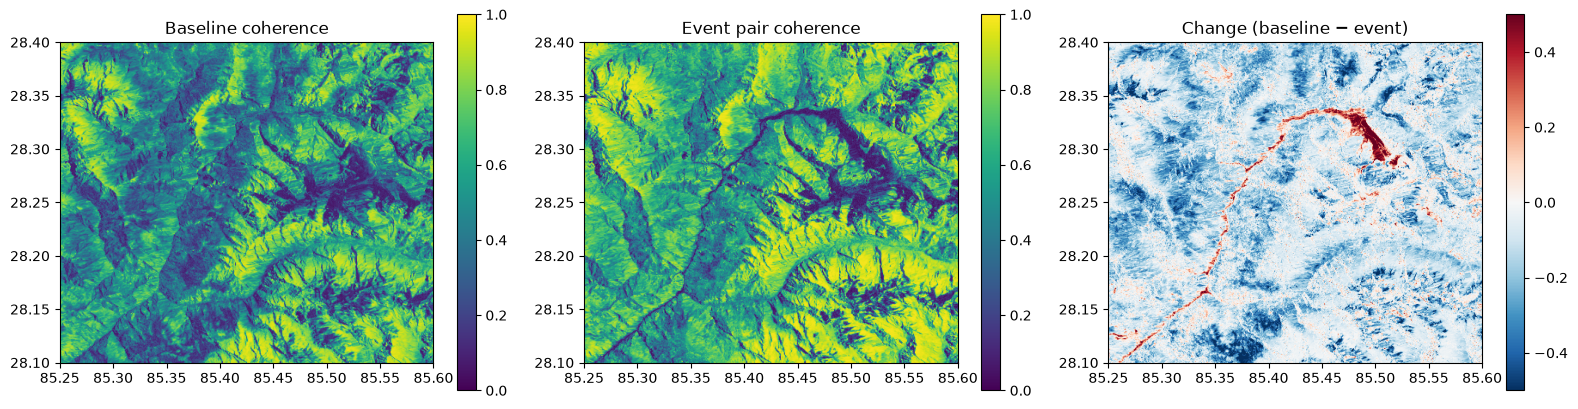

In [54]:
import matplotlib.pyplot as plt

# baseline, event pair and change side by side, north up
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
extent = [west, east, south, north]
for ax, data, title, cmap, vmin, vmax in zip(axes, [baseline, event_coherence, change],
                                              ["Baseline coherence", "Event pair coherence", "Change (baseline − event)"],
                                              ["viridis", "viridis", "RdBu_r"], [0, 0, -0.5], [1, 1, 0.5]):
    im = ax.imshow(data, extent=extent, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Reading the three maps**

- **Baseline coherence**: what's normal for each spot. Bright (yellow) is ground that stays the same from pass to pass, dark (purple) is ground that always changes: steep shaded slopes, snow and ice, and dense forest

- **Event pair coherence**: the same, for Aug 19 → Aug 31. A dark line now runs along the river, and the Lhende valley in the upper right goes dark

- **Change (baseline − event)**: red where the event pair is less coherent than normal (the ground changed), blue where it's more coherent than normal, white no difference

The red traces the whole path: a wide patch at the collapse site in the Lhende valley (about 85.47 to 85.52°E, 28.29 to 28.34°N), a thin line west along the valley, then south-west down the Bhote Koshi to the bottom-left corner toward Syabrubesi. The light blue everywhere else is the wider, drier pattern from the point above, not damage

<br/>

**Backscatter before and after**

Coherence shows *where* the ground changed. Backscatter from the GCOV passes either side of the event shows *how*: HV drops where vegetation was stripped or buried, HH can brighten with fresh debris or darken where water ponds ([Intro to SAR](https://www.earthdata.nasa.gov/learn/earth-observation-data-basics/sar))

Backscatter is power, which spans a huge range, so it's converted to **decibels (dB)**: `10 × log10(power)`. The difference in dB is then the change, positive brighter, negative darker

In [55]:
# function to read one polarization over the study area in dB, with the mask applied
def read_db(url, layer):
    """
    Read GCOV backscatter over the study area in decibels

    Args:
        url: The .h5 download link of the pass
        layer: "HHHH" or "HVHV"

    Returns:
        2D array in dB, nan where the mask says the pixel is invalid
    """
    with open_h5(url) as f:
        grid = f["science/LSAR/GCOV/grids/frequencyA"]
        rows, cols = aoi_window(grid)
        power = grid[layer][rows, cols]
        valid = (grid["mask"][rows, cols] >= 1) & (grid["mask"][rows, cols] <= 5) & (power > 0)
    return np.where(valid, 10 * np.log10(np.where(valid, power, 1)), np.nan)

In [ ]:
# last pass before and first pass after the event in the same stack
pre, post = before.loc[best_stack], after.loc[best_stack]
backscatter = {f"{name} {layer}": read_db(p.url, layer) for name, p in [("before", pre), ("after", post)] for layer in ["HHHH", "HVHV"]}

# change in dB, after minus before
for layer in ["HHHH", "HVHV"]:
    diff = backscatter[f"after {layer}"] - backscatter[f"before {layer}"]
    print(f"{layer}: mean change {np.nanmean(diff):+.2f} dB, pixels darker than -3 dB: {np.nansum(diff < -3):,}, brighter than +3 dB: {np.nansum(diff > 3):,}")

# this reads the 10 m layers, about 45 MB per layer over the box, so it takes a few minutes

HHHH: mean change -0.00 dB, pixels darker than -3 dB: 1,014,757, brighter than +3 dB: 1,010,080
HVHV: mean change -0.04 dB, pixels darker than -3 dB: 1,125,302, brighter than +3 dB: 1,062,896


At 10 m, these counts are mostly **speckle**: the grainy noise every radar image has, which is why about a million pixels go darker by 3 dB and about as many go brighter, and the mean change is about zero ([Intro to SAR](https://www.earthdata.nasa.gov/learn/earth-observation-data-basics/sar))

To see past the speckle, average neighbouring pixels (what the guide calls multi-looking), here 5 x 5 pixels into one 50 m pixel ([Intro to SAR](https://www.earthdata.nasa.gov/learn/earth-observation-data-basics/sar))

In [58]:
# function to average k x k blocks of pixels, in power rather than dB so bright pixels count properly
def multilook(db, k=5):
    """
    Average k x k blocks of a dB image to reduce speckle

    Args:
        db: 2D array in dB
        k: Block size in pixels, 5 turns 10 m pixels into 50 m

    Returns:
        Smaller 2D array in dB
    """
    h, w = (db.shape[0] // k) * k, (db.shape[1] // k) * k
    power = 10 ** (db[:h, :w] / 10)
    blocks = power.reshape(h // k, k, w // k, k)
    # blocks where every pixel is masked stay nan, instead of warning about an empty mean
    count = np.sum(~np.isnan(blocks), axis=(1, 3))
    mean = np.where(count > 0, np.nansum(blocks, axis=(1, 3)) / np.maximum(count, 1), np.nan)
    return 10 * np.log10(mean)

smooth = {name: multilook(image) for name, image in backscatter.items()}

# change in dB after averaging, after minus before
for layer in ["HHHH", "HVHV"]:
    diff = smooth[f"after {layer}"] - smooth[f"before {layer}"]
    print(f"{layer}: pixels darker than -3 dB: {np.nansum(diff < -3):,}, brighter than +3 dB: {np.nansum(diff > 3):,}")

/var/folders/qt/hcj8mn3s4rq62dxlffdwnnzw0000gn/T/ipykernel_96051/3663707869.py:15: RuntimeWarning: Mean of empty slice
  return 10 * np.log10(np.nanmean(power.reshape(h // k, k, w // k, k), axis=(1, 3)))


HHHH: pixels darker than -3 dB: 5,070, brighter than +3 dB: 5,373
HVHV: pixels darker than -3 dB: 5,916, brighter than +3 dB: 4,558


Averaging cuts the pixels changing by more than 3 dB from about a million to about 5,000 each way, so most of what's left is real change rather than speckle

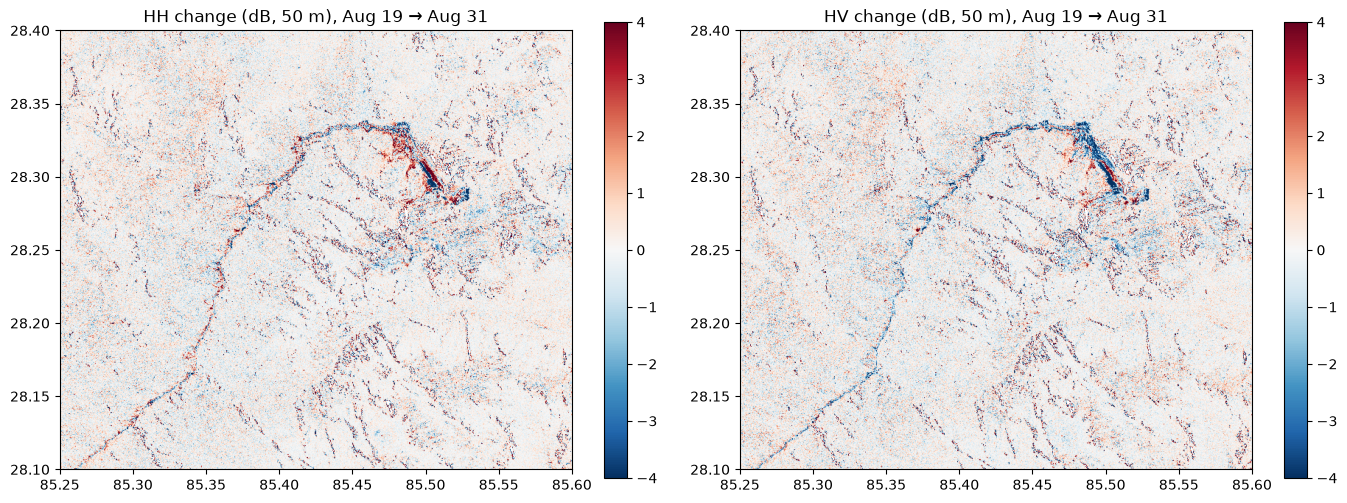

In [59]:
# averaged change maps, red = brighter after, blue = darker after
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, layer in zip(axes, ["HHHH", "HVHV"]):
    im = ax.imshow(smooth[f"after {layer}"] - smooth[f"before {layer}"], extent=extent, cmap="RdBu_r", vmin=-4, vmax=4)
    ax.set_title(f"{layer[:2]} change (dB, 50 m), {pre.start:%b %d} → {post.start:%b %d}")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Reading the change maps** (blue = darker after, red = brighter after)

- **HV** (right) shows the path clearly: a blue line along the whole river, from the Lhende valley down the Bhote Koshi to the bottom-left corner, and a strong blue strip at the collapse site (about 85.49 to 85.52°E, 28.29 to 28.33°N). Darker HV means less vegetation, so the flood stripped or buried the plants along its path

- **HH** (left) shows the same path, but mixed: blue along the river and through the middle of the collapse site, with red around its edges. Brighter HH fits fresh, rough debris dumped at the sides, darker HH a smoother surface where it was scoured or covered in fine sediment and water

- The short dark and red streaks scattered across the slopes are steep, radar-facing slopes, not change, they come from the terrain rather than the event

So HV is the better layer for mapping the damage, and HH adds detail on what the surface turned into

Section 3 shows the collapse clearly in the data:

- The `098_A_016` passes on Aug 19 and Aug 31 bracket the collapse, and NISAR switched the area to Urgent Response right after

- Coherence drops along the whole path, from the collapse site in the Lhende valley down the Bhote Koshi, about 11 km² in total

- Backscatter, averaged to 50 m, shows how the surface changed: HV darkens along the path where vegetation was stripped, and HH brightens with debris at the collapse site

Next is section 4: turning these results into small files the application can use

<br/>
<br/>

### 4. Data Processing 